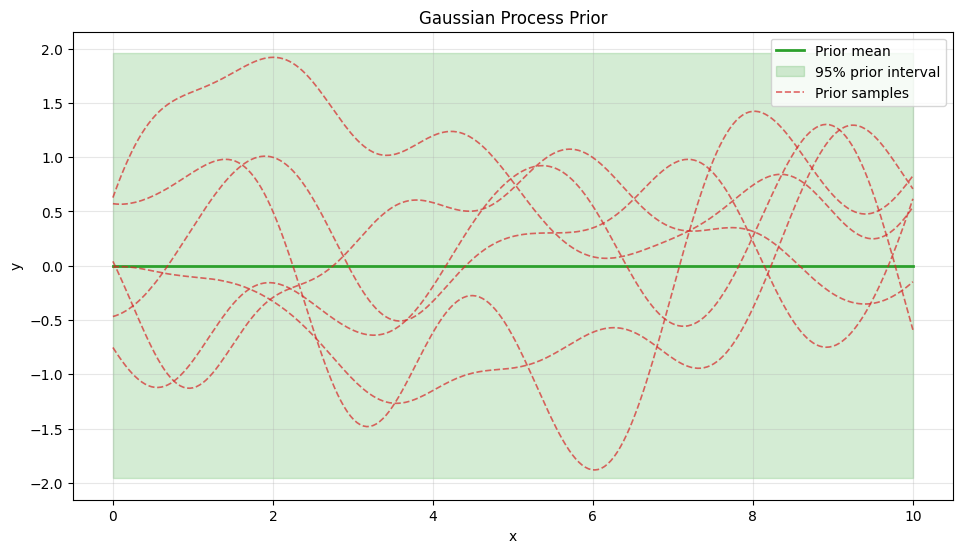

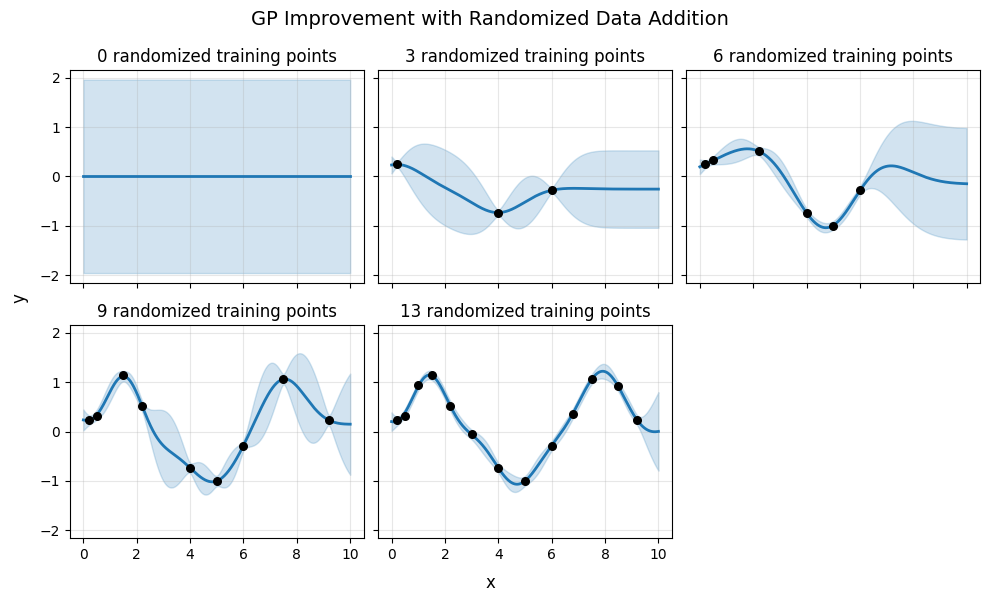

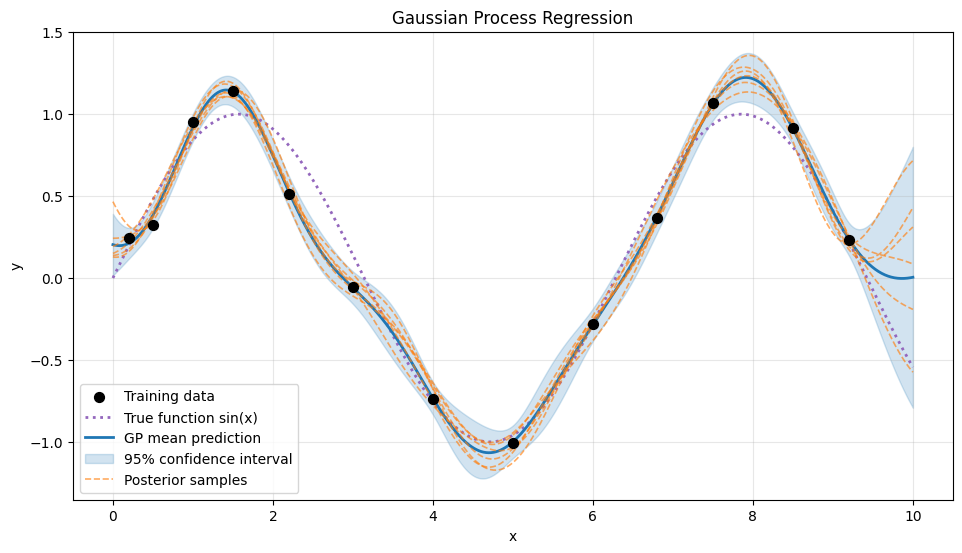

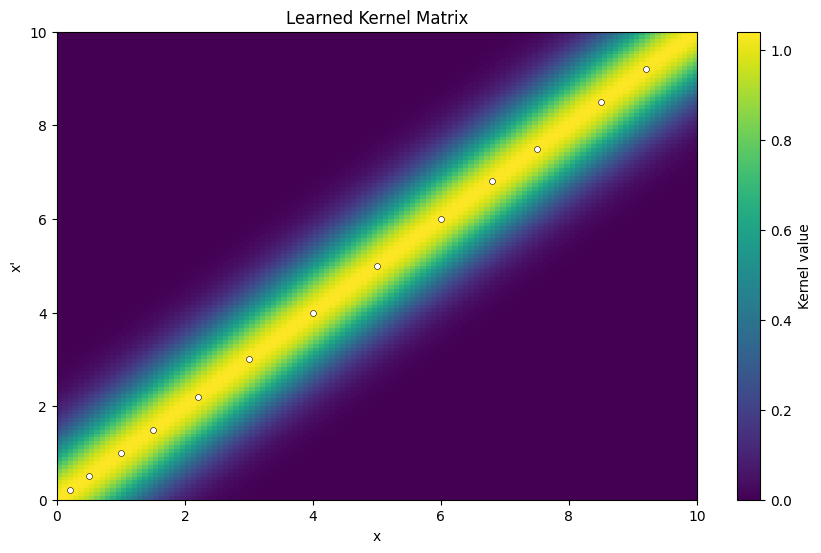

Learned kernel: 1.02**2 * RBF(length_scale=0.892)


: 

In [ ]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C

# Shared figure geometry for consistent output across all plots
FIG_SIZE = (10, 6)
FIG_DPI = 100

# Ensure notebook output keeps a fixed canvas size (no tight-bbox auto-cropping)
mpl.rcParams["figure.figsize"] = FIG_SIZE
mpl.rcParams["figure.dpi"] = FIG_DPI
mpl.rcParams["savefig.bbox"] = None

# -----------------------------
# 1. Training data
# -----------------------------
rng = np.random.default_rng(42)

X_train = np.array([0.2, 0.5, 1.0, 1.5, 2.2, 3.0, 4.0, 5.0, 6.0, 6.8, 7.5, 8.5, 9.2]).reshape(-1, 1)
y_train = np.sin(X_train).ravel() + rng.normal(0, 0.15, size=X_train.shape[0])

# -----------------------------
# 2. Test grid
# -----------------------------
X_test = np.linspace(0, 10, 1000).reshape(-1, 1)
X_prior = np.linspace(0, 10, 250).reshape(-1, 1)

# -----------------------------
# 3. Define GP model
# -----------------------------
kernel = C(1.0, (1e-3, 1e3)) * RBF(length_scale=1.0, length_scale_bounds=(1e-2, 1e2))
gp_kwargs = dict(
    kernel=kernel,
    alpha=0.08**2,          # lower noise gives higher confidence near training data
    n_restarts_optimizer=10,
    normalize_y=True,
    random_state=42
)
gp = GaussianProcessRegressor(**gp_kwargs)

# -----------------------------
# 4. Visualize GP prior
# -----------------------------
prior_mean = np.zeros(X_prior.shape[0])
K_prior = kernel(X_prior)
prior_std = np.sqrt(np.clip(np.diag(K_prior), 0, None))
prior_lower = prior_mean - 1.96 * prior_std
prior_upper = prior_mean + 1.96 * prior_std
prior_samples = rng.multivariate_normal(
    mean=prior_mean,
    cov=K_prior + 1e-8 * np.eye(X_prior.shape[0]),
    size=6
).T

fig, axis = plt.subplots(figsize=FIG_SIZE, dpi=FIG_DPI)
axis.plot(X_prior, prior_mean, color="tab:green", lw=2, label="Prior mean")
axis.fill_between(
    X_prior.ravel(),
    prior_lower,
    prior_upper,
    color="tab:green",
    alpha=0.2,
    label="95% prior interval"
)

for index in range(prior_samples.shape[1]):
    label = "Prior samples" if index == 0 else None
    axis.plot(
        X_prior,
        prior_samples[:, index],
        color="tab:red",
        lw=1.2,
        alpha=0.7,
        linestyle="--",
        label=label
    )

axis.set_title("Gaussian Process Prior")
axis.set_xlabel("x")
axis.set_ylabel("y")
axis.legend()
axis.grid(alpha=0.3)
fig.subplots_adjust(left=0.10, right=0.98, top=0.90, bottom=0.12)
plt.show()

# -----------------------------
# 5. Step-by-step GP improvement
# -----------------------------
stage_rng = np.random.default_rng(7)
random_order = stage_rng.permutation(len(X_train))
X_stage_order = X_train[random_order]
y_stage_order = y_train[random_order]
stage_sizes = [0, 3, 6, 9, len(X_train)]

# Use a 2x3 layout to include the 0-point prior panel
fig, axes = plt.subplots(2, 3, figsize=FIG_SIZE, dpi=FIG_DPI, sharex=True, sharey=True)
axes = axes.ravel()

for axis, stage_size in zip(axes, stage_sizes):
    gp_stage = GaussianProcessRegressor(**gp_kwargs)
    X_stage = X_stage_order[:stage_size]
    y_stage = y_stage_order[:stage_size]

    if stage_size == 0:
        # Untrained GP prediction equals the prior
        y_stage_mean = np.zeros(X_test.shape[0])
        y_stage_std = np.sqrt(np.clip(np.diag(kernel(X_test)), 0, None))
    else:
        gp_stage.fit(X_stage, y_stage)
        y_stage_mean, y_stage_std = gp_stage.predict(X_test, return_std=True)
    y_stage_lower = y_stage_mean - 1.96 * y_stage_std
    y_stage_upper = y_stage_mean + 1.96 * y_stage_std

    if stage_size > 0:
        sort_index = np.argsort(X_stage.ravel())
        X_stage_plot = X_stage[sort_index]
        y_stage_plot = y_stage[sort_index]
        axis.scatter(X_stage_plot, y_stage_plot, color="black", s=30, zorder=3)
    axis.plot(X_test, y_stage_mean, color="tab:blue", lw=2)
    axis.fill_between(
        X_test.ravel(),
        y_stage_lower,
        y_stage_upper,
        color="tab:blue",
        alpha=0.2
    )
    axis.set_title(f"{stage_size} randomized training points")
    axis.grid(alpha=0.3)

for axis in axes[len(stage_sizes):]:
    axis.set_visible(False)

fig.suptitle("GP Improvement with Randomized Data Addition", fontsize=14)
fig.supxlabel("x")
fig.supylabel("y")
fig.subplots_adjust(left=0.08, right=0.99, top=0.88, bottom=0.10, wspace=0.05, hspace=0.20)
plt.show()

# -----------------------------
# 6. Fit and predict
# -----------------------------
gp.fit(X_train, y_train)
y_mean, y_std = gp.predict(X_test, return_std=True)
y_samples = gp.sample_y(X_test, n_samples=6, random_state=42)
y_true = np.sin(X_test).ravel()

# 95% confidence interval
y_lower = y_mean - 1.96 * y_std
y_upper = y_mean + 1.96 * y_std

# -----------------------------
# 7. GP fit plot
# -----------------------------
fig, axis = plt.subplots(figsize=FIG_SIZE, dpi=FIG_DPI)

axis.scatter(X_train, y_train, color="black", s=50, label="Training data", zorder=3)
axis.plot(X_test, y_true, color="tab:purple", lw=2, linestyle=":", label="True function sin(x)")
axis.plot(X_test, y_mean, color="tab:blue", lw=2, label="GP mean prediction")
axis.fill_between(
    X_test.ravel(),
    y_lower,
    y_upper,
    color="tab:blue",
    alpha=0.2,
    label="95% confidence interval"
)

for index in range(y_samples.shape[1]):
    label = "Posterior samples" if index == 0 else None
    axis.plot(
        X_test,
        y_samples[:, index],
        color="tab:orange",
        lw=1.2,
        alpha=0.65,
        linestyle="--",
        label=label
    )

axis.set_title("Gaussian Process Regression")
axis.set_xlabel("x")
axis.set_ylabel("y")
axis.legend()
axis.grid(alpha=0.3)
fig.subplots_adjust(left=0.10, right=0.98, top=0.90, bottom=0.12)
plt.show()

# -----------------------------
# 8. Kernel visualization
# -----------------------------
X_kernel = np.linspace(0, 10, 120).reshape(-1, 1)
K = gp.kernel_(X_kernel)

fig, axis = plt.subplots(figsize=FIG_SIZE, dpi=FIG_DPI)
image = axis.imshow(
    K,
    origin="lower",
    extent=[X_kernel.min(), X_kernel.max(), X_kernel.min(), X_kernel.max()],
    cmap="viridis",
    aspect="auto"
)
fig.colorbar(image, ax=axis, label="Kernel value")
axis.scatter(X_train.ravel(), X_train.ravel(), color="white", s=18, edgecolor="black", linewidth=0.4)
axis.set_title("Learned Kernel Matrix")
axis.set_xlabel("x")
axis.set_ylabel("x'")
fig.subplots_adjust(left=0.10, right=0.90, top=0.90, bottom=0.12)
plt.show()

print("Learned kernel:", gp.kernel_)